# UA-DETRAC Data Preparation Notebook (Person 1 - Rish Jain)

1. Import Libraries

In [33]:
#Install libraries
%pip install -q gdown pandas numpy matplotlib pyyaml pillow scikit-learn


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [34]:
#Import libraries
import random
import shutil
import zipfile
import xml.etree.ElementTree as ET
from pathlib import Path

import gdown
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from PIL import Image, ImageDraw
from sklearn.model_selection import train_test_split

#Set random seed
random.seed(42)
np.random.seed(42)

2. Set Up Folders and Variables

In [35]:
#Main project folders
project_dir = Path('/content/traffic-monitoring') if Path('/content').exists() else (Path.cwd() if Path.cwd().name == 'traffic-monitoring' else Path.cwd() / 'traffic-monitoring')
zip_dir = project_dir / 'data' / 'zip'
raw_dir = project_dir / 'data' / 'raw'
processed_dir = project_dir / 'data' / 'processed'
figure_dir = project_dir / 'outputs' / 'figures'

#Create folders
for folder in [zip_dir, raw_dir, processed_dir, figure_dir]:
    folder.mkdir(parents=True, exist_ok=True)

#Dataset settings
max_sequences = 36
frame_step = 5

#Vehicle classes used by UA-DETRAC
class_names = ['car', 'bus', 'van', 'others']
class_ids = {name: i for i, name in enumerate(class_names)}

3. Extract Dataset Archives


In [36]:
#Extract all zip files from data/zip into data/raw if not already extracted
zip_files = sorted(zip_dir.glob('*.zip'))

for zip_file in zip_files:
    if 'Images' in zip_file.name:
        target_dir = raw_dir / 'DETRAC-Images'
        already_extracted = target_dir.exists() and any(target_dir.iterdir())
    else:
        already_extracted = any(raw_dir.rglob(f'{zip_file.stem}/*.xml')) or any(raw_dir.glob(f'{zip_file.stem}/*.xml'))

    if not already_extracted:
        print(f'Extracting: {zip_file.name} to {raw_dir}')
        with zipfile.ZipFile(zip_file, 'r') as zip_ref:
            zip_ref.extractall(raw_dir)
    else:
        print(f'Already extracted: {zip_file.name}')

print('Extraction step complete')

Already extracted: DETRAC-Images.zip
Already extracted: DETRAC-Test-Annotations-XML.zip
Already extracted: DETRAC-Train-Annotations-XML.zip
Extraction step complete


4. Match Image Sequences with XML Files


In [37]:
#Find XML files in data/raw
xml_files = sorted(raw_dir.rglob('MVI_*.xml'))

#Find folders that contain sequence images in data/raw
image_folders = {}
for folder in (raw_dir / 'DETRAC-Images').glob('MVI_*'):
    if folder.is_dir() and list(folder.glob('img*.jpg')):
        image_folders[folder.name] = folder

#Match each sequence with its XML file
sequence_data = []

for xml_file in xml_files:
    sequence_name = xml_file.stem

    if sequence_name in image_folders:
        root = ET.parse(xml_file).getroot()
        weather = root.attrib.get('sence_weather', root.attrib.get('weather', 'unknown'))
        frames = root.findall('./frame')
        object_count = sum(len(frame.findall('./target_list/target')) for frame in frames)

        sequence_data.append({
            'sequence': sequence_name,
            'image_folder': image_folders[sequence_name],
            'xml_file': xml_file,
            'weather': weather,
            'frames': len(frames),
            'objects': object_count
        })

sequence_df = pd.DataFrame(sequence_data)

if len(sequence_df) == 0:
    raise ValueError('No matching image and XML sequences were found')

print(f'Found {len(image_folders)} image sequences and {len(xml_files)} XML files.')
print('Matched sequences:', len(sequence_df))
display(sequence_df[['sequence', 'weather', 'frames', 'objects']].head())

Found 100 image sequences and 100 XML files.
Matched sequences: 100


,sequence,weather,frames,objects
0,MVI_39031,unknown,1470,10354
1,MVI_39051,unknown,1051,2443
2,MVI_39211,unknown,1566,4329
3,MVI_39271,unknown,1566,8502
4,MVI_39311,unknown,1505,22457


5. Split by Video Sequence

The split is done by complete sequence instead of individual frame. This prevents nearly identical frames from appearing in both training and testing.

In [38]:
#Shuffle and limit the number of sequences
sequence_df = sequence_df.sample(frac=1, random_state=42).reset_index(drop=True)

if max_sequences is not None:
    sequence_df = sequence_df.head(max_sequences).copy()

#70% training, 15% validation, 15% testing
train_sequences, temp_sequences = train_test_split(
    sequence_df['sequence'],
    test_size=0.30,
    random_state=42
)

val_sequences, test_sequences = train_test_split(
    temp_sequences,
    test_size=0.50,
    random_state=42
)

#Assign each sequence to one split
split_dict = {}

for sequence in train_sequences:
    split_dict[sequence] = 'train'

for sequence in val_sequences:
    split_dict[sequence] = 'val'

for sequence in test_sequences:
    split_dict[sequence] = 'test'

sequence_df['split'] = sequence_df['sequence'].map(split_dict)

display(sequence_df[['sequence', 'weather', 'split']])
print(sequence_df['split'].value_counts())

,sequence,weather,split
0,MVI_40871,unknown,train
1,MVI_39761,unknown,train
2,MVI_40191,unknown,train
3,MVI_20035,unknown,train
4,MVI_20034,unknown,train
5,MVI_40905,unknown,train
6,MVI_40774,unknown,train
7,MVI_40732,unknown,train
8,MVI_40701,unknown,val
9,MVI_39031,unknown,test


split
train    25
test      6
val       5
Name: count, dtype: int64


6. Convert Bounding Boxes to YOLO Format

In [39]:
def get_vehicle_type(target):
    #Read the vehicle type from the XML target
    attributes = target.find('./attribute')

    if attributes is None:
        return 'others'

    vehicle_type = attributes.attrib.get('vehicle_type', 'others').lower()

    if vehicle_type == 'other':
        vehicle_type = 'others'

    if vehicle_type not in class_names:
        vehicle_type = 'others'

    return vehicle_type


def convert_box(box, image_width, image_height):
    #Read original pixel coordinates
    left = float(box.attrib['left'])
    top = float(box.attrib['top'])
    width = float(box.attrib['width'])
    height = float(box.attrib['height'])

    #Keep the box inside the image
    left = max(0, min(left, image_width))
    top = max(0, min(top, image_height))
    right = max(0, min(left + width, image_width))
    bottom = max(0, min(top + height, image_height))

    width = right - left
    height = bottom - top

    if width <= 1 or height <= 1:
        return None

    #Convert to normalized YOLO coordinates
    x_center = (left + width / 2) / image_width
    y_center = (top + height / 2) / image_height
    yolo_width = width / image_width
    yolo_height = height / image_height

    return left, top, width, height, x_center, y_center, yolo_width, yolo_height

In [40]:
#Clear old processed files before rebuilding the dataset
if processed_dir.exists():
    shutil.rmtree(processed_dir)

#Create image and label folders for each split
for split in ['train', 'val', 'test']:
    (processed_dir / 'images' / split).mkdir(parents=True, exist_ok=True)
    (processed_dir / 'labels' / split).mkdir(parents=True, exist_ok=True)

frame_rows = []
annotation_rows = []

#Process one video sequence at a time
for row in sequence_df.itertuples():
    root = ET.parse(row.xml_file).getroot()

    #Match frame numbers to XML and image files
    xml_frames = {int(frame.attrib['num']): frame for frame in root.findall('./frame')}
    image_files = {
        int(path.stem.replace('img', '')): path
        for path in Path(row.image_folder).glob('img*.jpg')
    }

    for frame_number in sorted(xml_frames.keys()):
        #Use every fifth frame to reduce repeated images
        if (frame_number - 1) % frame_step != 0:
            continue

        if frame_number not in image_files:
            continue

        source_image = image_files[frame_number]
        image = Image.open(source_image).convert('RGB')
        image_width, image_height = image.size

        file_name = f'{row.sequence}_img{frame_number:05d}'
        output_image = processed_dir / 'images' / row.split / f'{file_name}.jpg'
        output_label = processed_dir / 'labels' / row.split / f'{file_name}.txt'

        image.save(output_image)

        label_lines = []
        frame_object_count = 0

        for target in xml_frames[frame_number].findall('./target_list/target'):
            box = target.find('./box')

            if box is None:
                continue

            converted_box = convert_box(box, image_width, image_height)

            if converted_box is None:
                continue

            left, top, width, height, x_center, y_center, yolo_width, yolo_height = converted_box
            vehicle_type = get_vehicle_type(target)
            class_id = class_ids[vehicle_type]

            label_lines.append(
                f'{class_id} {x_center:.6f} {y_center:.6f} {yolo_width:.6f} {yolo_height:.6f}'
            )

            annotation_rows.append({
                'sequence': row.sequence,
                'frame': frame_number,
                'split': row.split,
                'class_name': vehicle_type,
                'class_id': class_id,
                'left': left,
                'top': top,
                'width': width,
                'height': height,
                'area': (width * height) / (image_width * image_height),
                'image_path': str(output_image)
            })

            frame_object_count += 1

        output_label.write_text('\n'.join(label_lines))

        frame_rows.append({
            'sequence': row.sequence,
            'frame': frame_number,
            'split': row.split,
            'weather': row.weather,
            'image_path': str(output_image),
            'label_path': str(output_label),
            'objects': frame_object_count
        })

frame_df = pd.DataFrame(frame_rows)
annotation_df = pd.DataFrame(annotation_rows)

print('Frames prepared:', len(frame_df))
print('Bounding boxes prepared:', len(annotation_df))

Frames prepared: 10418
Bounding boxes prepared: 108025


7. Save Dataset Files

In [41]:
#Save CSV files for later analysis
frame_df.to_csv(processed_dir / 'frame_manifest.csv', index=False)
annotation_df.to_csv(processed_dir / 'annotations.csv', index=False)
sequence_df[['sequence', 'weather', 'frames', 'objects', 'split']].to_csv(
    processed_dir / 'sequence_split.csv',
    index=False
)

#Create the YAML file used by YOLO
data_yaml = {
    'path': str(processed_dir.resolve()),
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',
    'names': class_names
}

with open(processed_dir / 'data.yaml', 'w') as file:
    yaml.safe_dump(data_yaml, file, sort_keys=False)

print('Saved:', processed_dir / 'data.yaml')

Saved: /Users/rishjain/Downloads/DATA255/Project/traffic-monitoring/data/processed/data.yaml


8. Check the Processed Dataset

In [ ]:
#Check that every image has a label file
missing_labels = 0
invalid_coordinates = 0

for row in frame_df.itertuples():
    label_path = Path(row.label_path)

    if not label_path.exists():
        missing_labels += 1
        continue

    for line in label_path.read_text().splitlines():
        values = line.split()

        if len(values) != 5:
            invalid_coordinates += 1
            continue

        coordinates = [float(value) for value in values[1:]]

        if not all(0 <= value <= 1 for value in coordinates):
            invalid_coordinates += 1

#Check that a sequence only appears in one split
sequence_leakage = frame_df.groupby('sequence')['split'].nunique().max()

print('Missing labels:', missing_labels)
print('Invalid labels:', invalid_coordinates)
print('Maximum splits per sequence:', sequence_leakage)

assert missing_labels == 0
assert invalid_coordinates == 0
assert sequence_leakage == 1

print('Dataset checks passed')

Missing labels: 0
Invalid labels: 0
Maximum splits per sequence: 1
Dataset checks passed


9. Dataset Visualizations

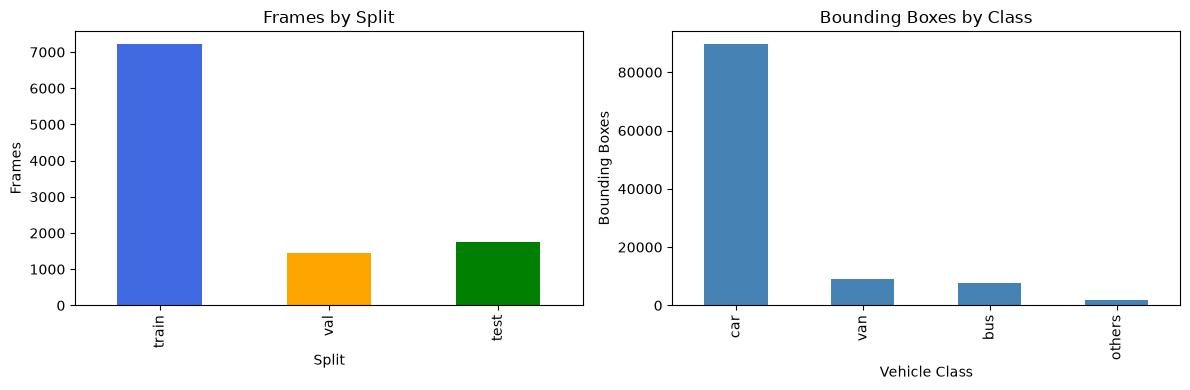

In [43]:
#Count frames and bounding boxes in each split
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

frame_df['split'].value_counts().reindex(['train', 'val', 'test']).plot(
    kind='bar',
    ax=axes[0],
    color=['royalblue', 'orange', 'green']
)
axes[0].set_title('Frames by Split')
axes[0].set_xlabel('Split')
axes[0].set_ylabel('Frames')

annotation_df['class_name'].value_counts().plot(
    kind='bar',
    ax=axes[1],
    color='steelblue'
)
axes[1].set_title('Bounding Boxes by Class')
axes[1].set_xlabel('Vehicle Class')
axes[1].set_ylabel('Bounding Boxes')

plt.tight_layout()
plt.savefig(figure_dir / 'dataset_summary.png', dpi=200)
plt.show()

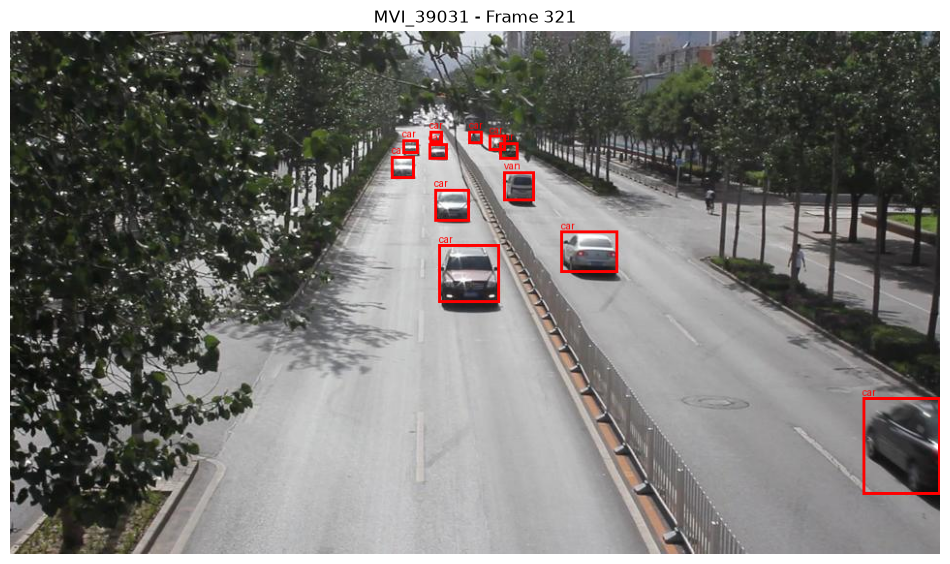

In [44]:
#Show one processed image with its bounding boxes
sample_row = frame_df.sample(1, random_state=42).iloc[0]
sample_image = Image.open(sample_row['image_path']).convert('RGB')
draw = ImageDraw.Draw(sample_image)

sample_boxes = annotation_df[
    (annotation_df['sequence'] == sample_row['sequence']) &
    (annotation_df['frame'] == sample_row['frame'])
]

for box in sample_boxes.itertuples():
    right = box.left + box.width
    bottom = box.top + box.height
    draw.rectangle([box.left, box.top, right, bottom], outline='red', width=3)
    draw.text((box.left, max(0, box.top - 12)), box.class_name, fill='red')

plt.figure(figsize=(12, 7))
plt.imshow(sample_image)
plt.title(f"{sample_row['sequence']} - Frame {sample_row['frame']}")
plt.axis('off')
plt.savefig(figure_dir / 'sample_annotation.png', dpi=200, bbox_inches='tight')
plt.show()

10. Final Output

In [45]:
#Display the final dataset summary
summary = frame_df.groupby('split').agg(
    sequences=('sequence', 'nunique'),
    frames=('frame', 'count'),
    objects=('objects', 'sum')
).reindex(['train', 'val', 'test'])

display(summary)
display(pd.crosstab(annotation_df['class_name'], annotation_df['split']))

print('Data preparation successful')
print('Processed dataset:', processed_dir)
print('YOLO configuration:', processed_dir / 'data.yaml')
print('Figures:', figure_dir)

,sequences,frames,objects
split,,,
train,25,7212,77830
val,5,1461,12212
test,6,1745,17983


split,test,train,val
class_name,,,
bus,372,6605,542
car,15758,63630,10168
others,389,1164,298
van,1464,6431,1204


Data preparation successful
Processed dataset: /Users/rishjain/Downloads/DATA255/Project/traffic-monitoring/data/processed
YOLO configuration: /Users/rishjain/Downloads/DATA255/Project/traffic-monitoring/data/processed/data.yaml
Figures: /Users/rishjain/Downloads/DATA255/Project/traffic-monitoring/outputs/figures
